# INK / Digit Inspector | ML Assignment 2

**Experiment objective.** Classify handwritten digits **0–9** using **five algorithms** and compare Accuracy, ROC AUC, Precision, Recall, F1 and MCC using one held-out test partition. Export fully fitted preprocessing+model pipelines for an inference-only Streamlit evaluation app.

**Public provenance.** The dataset is scikit-learn’s documented **1,797-image copy of the test subset of the UCI Optical Recognition of Handwritten Digits dataset**. UCI source: https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits. scikit-learn loader: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html. The raw 64-feature CSV is bundled in `data/digits_uci_subset.csv` to avoid downloads.

**Important evaluation policy:** fixed stratified 80/20 split, `random_state=37`. Scaling is fitted *only on the training portion* inside each model’s pipeline. Multiclass precision, recall, F1 are **macro** averages; AUC is **macro one-vs-rest** using class probabilities; MCC is the **multiclass** coefficient. The app only loads saved models; it cannot train on an uploaded CSV.

## 1 — Reproducible environment and input data

In [1]:
from pathlib import Path
import json, hashlib, sys
import joblib, numpy as np, pandas as pd, sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
from src.data_io import validate_labeled_csv
from src.experiment import SEED, TEST_FRACTION, TARGET, PIXELS, CLASSES, MODEL_FILES, make_models
from src.metrics import METRICS, evaluate, winner_by_mcc

ROOT = Path.cwd()
raw = pd.read_csv(ROOT / 'data' / 'digits_uci_subset.csv')
X, y = validate_labeled_csv(raw)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)
print('Dataset:', raw.shape, '| input features:', len(PIXELS), '| classes:', y.nunique())
display(raw.head(3))
assert raw.shape == (1797, 65) and len(PIXELS) >= 12
assert len(raw) >= 500

Python: 3.11.9 | scikit-learn: 1.9.0
Dataset: (1797, 65) | input features: 64 | classes: 10


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,Digit
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2


## 2 — Data understanding and quality checks

Pixel columns are **numerical integer counts from 0 through 16**. The last column `Digit` is the ten-class target. Inspect missing values, duplicates, type information, class balance and constant features before modeling. The classifier sees a 64-dimensional feature vector, not raw 32×32 photographs.

Schema and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1797 entries, 0 to 1796
Data columns (total 65 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pixel_0_0  1797 non-null   float64
 1   pixel_0_1  1797 non-null   float64
 2   pixel_0_2  1797 non-null   float64
 3   pixel_0_3  1797 non-null   float64
 4   pixel_0_4  1797 non-null   float64
 5   pixel_0_5  1797 non-null   float64
 6   pixel_0_6  1797 non-null   float64
 7   pixel_0_7  1797 non-null   float64
 8   pixel_1_0  1797 non-null   float64
 9   pixel_1_1  1797 non-null   float64
 10  pixel_1_2  1797 non-null   float64
 11  pixel_1_3  1797 non-null   float64
 12  pixel_1_4  1797 non-null   float64
 13  pixel_1_5  1797 non-null   float64
 14  pixel_1_6  1797 non-null   float64
 15  pixel_1_7  1797 non-null   float64
 16  pixel_2_0  1797 non-null   float64
 17  pixel_2_1  1797 non-null   float64
 18  pixel_2_2  1797 non-null   float64
 19  pixel_2_3  1797 non-null   floa

,count,percentage
Digit,,
0,178,9.905398
1,182,10.127991
2,177,9.849750
3,183,10.183639
4,181,10.072343
5,182,10.127991
6,181,10.072343
7,179,9.961046
8,174,9.682805


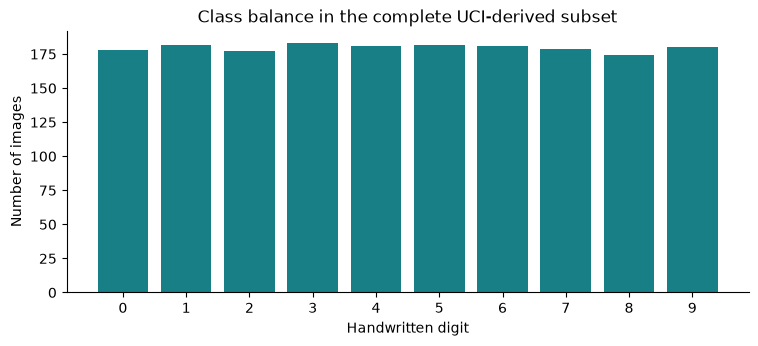

In [2]:
print('Schema and non-null counts:')
raw.info()
print('\nMissing values in entire dataset:', int(raw.isna().sum().sum()))
print('Duplicate rows:', int(raw.duplicated().sum()))
print('Constant pixel columns:', [c for c in PIXELS if raw[c].nunique() == 1])
class_table = pd.DataFrame({'count': y.value_counts().sort_index()})
class_table['percentage'] = 100 * class_table['count'] / len(y)
display(class_table)
fig, ax = plt.subplots(figsize=(8.8, 3.4))
ax.bar(class_table.index.astype(str), class_table['count'], color='#177F85')
ax.set(xlabel='Handwritten digit', ylabel='Number of images', title='Class balance in the complete UCI-derived subset')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 3 — See what the 64 predictor columns represent

Each sample can be reconstructed into an 8 × 8 intensity grid. Display one genuine example of each digit **before** fitting models.

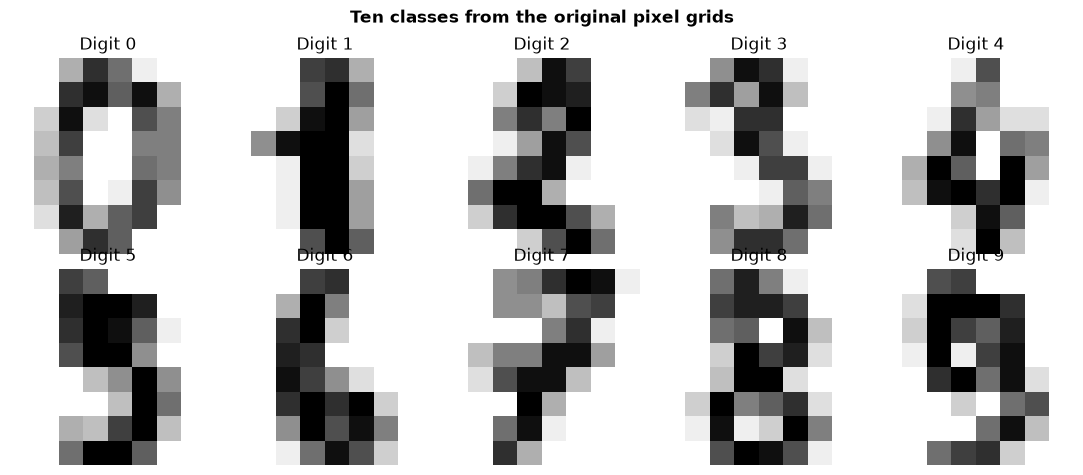

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
for digit, ax in zip(CLASSES, axes.flat):
    sample = X.iloc[np.flatnonzero(y.to_numpy() == digit)[0]].to_numpy().reshape(8, 8)
    ax.imshow(sample, cmap='binary', vmin=0, vmax=16, interpolation='nearest')
    ax.set_title(f'Digit {digit}'); ax.axis('off')
fig.suptitle('Ten classes from the original pixel grids', fontweight='bold')
plt.tight_layout();plt.show()

## 4 — Split first, preprocess inside the pipeline

The **identical** stratified hold-out split is used by all five classifiers. `make_models()` creates **five fresh pipelines**, each with a `ColumnTransformer(StandardScaler)` followed by an estimator. Even constant columns are safely handled by scikit-learn’s scaler. No scaler is fitted to the complete dataset.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_FRACTION, random_state=SEED, stratify=y
)
print('Training images:', len(X_train), '| held-out test images:', len(X_test))
print('Training target counts:', y_train.value_counts().sort_index().to_dict())
print('Test target counts:', y_test.value_counts().sort_index().to_dict())
assert X_train.index.is_unique and len(set(X_train.index) & set(X_test.index)) == 0

Training images: 1437 | held-out test images: 360
Training target counts: {0: 142, 1: 146, 2: 142, 3: 146, 4: 145, 5: 145, 6: 145, 7: 143, 8: 139, 9: 144}
Test target counts: {0: 36, 1: 36, 2: 35, 3: 37, 4: 36, 5: 37, 6: 36, 7: 36, 8: 35, 9: 36}


## 5 — Train five required classifiers

Settings: Logistic Regression (`C=0.7`, `max_iter=2500`), Decision Tree (`max_depth=12`, `min_samples_leaf=2`), KNN (`k=5`, distance weighting), Gaussian Naive Bayes (`var_smoothing=1e-8`), and SVM (`RBF`, `C=4`, `probability=True`). These settings are fixed in `src/experiment.py` and shared with `train.py`.

In [5]:
trained_models = make_models(PIXELS)
for name, pipeline in trained_models.items():
    pipeline.fit(X_train, y_train)
    assert np.array_equal(pipeline.classes_, CLASSES)
    print(f'Trained: {name} | fitted preprocessing + model')

Trained: Logistic Regression | fitted preprocessing + model
Trained: Decision Tree | fitted preprocessing + model
Trained: K-Nearest Neighbors | fitted preprocessing + model
Trained: Gaussian Naive Bayes | fitted preprocessing + model
Trained: Support Vector Machine | fitted preprocessing + model


/Users/sanyukta/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 6 — All six metrics, exactly the same definition for all models

For 10-class data, **macro precision/recall/F1** give all digits equal importance, **AUC** summarizes ten one-vs-rest ranking curves from `predict_proba`, and **MCC** is the multiclass correlation measure. AUC must not be computed from hard class predictions.

In [6]:
rows, matrices = [], {}
for name, pipeline in trained_models.items():
    scores, cm, pred, prob = evaluate(pipeline, X_test, y_test)
    rows.append({'ML Model Name': name, **scores})
    matrices[name] = cm
comparison = pd.DataFrame(rows)[['ML Model Name', *METRICS]]
print('Test set rows:', len(X_test))
display(comparison.style.format({metric: '{:.4f}' for metric in METRICS}))
print('MCC/F1 winner:', winner_by_mcc(comparison))
assert all(np.isfinite(comparison[m]).all() for m in METRICS)

Test set rows: 360


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9917,0.9997,0.9919,0.9918,0.9917,0.9908
1,Decision Tree,0.8500,0.9289,0.8580,0.8492,0.8507,0.8340
2,K-Nearest Neighbors,0.9833,0.9953,0.9839,0.9831,0.9833,0.9815
3,Gaussian Naive Bayes,0.8278,0.9732,0.8462,0.8275,0.8263,0.8111
4,Support Vector Machine,0.9889,0.9999,0.9890,0.9889,0.9888,0.9877


MCC/F1 winner: Logistic Regression


## 7 — Model comparison plots

A high accuracy alone is not enough to decide between classifiers. We inspect **MCC, macro F1 and macro OvR AUC** and compare how many rows are misclassified.

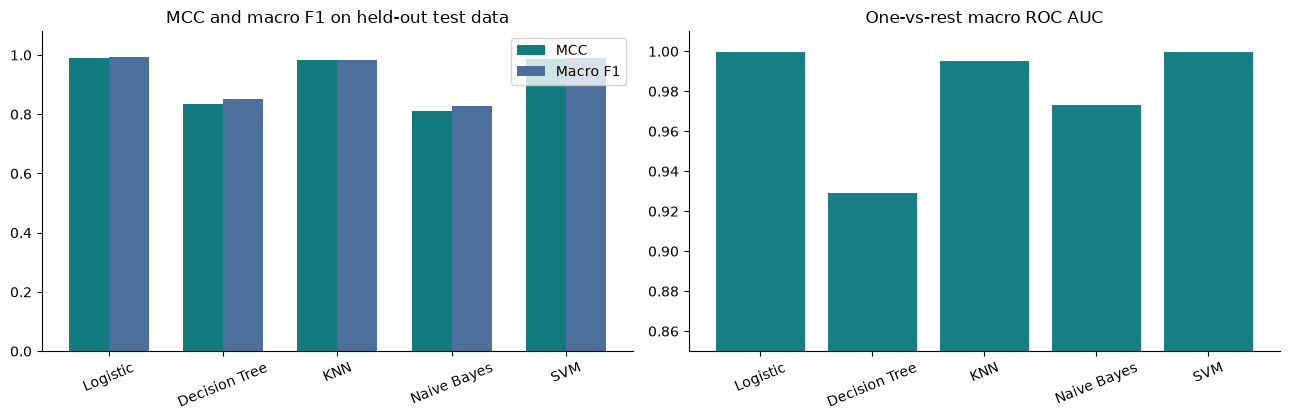

In [7]:
names = comparison['ML Model Name'].tolist()
short_names = ['Logistic', 'Decision Tree', 'KNN', 'Naive Bayes', 'SVM']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
x = np.arange(5); width=.35
axes[0].bar(x-width/2, comparison['MCC'], width, color='#127b80', label='MCC')
axes[0].bar(x+width/2, comparison['F1'], width, color='#4c6f9c', label='Macro F1')
axes[0].set_ylim(0,1.08); axes[0].set_xticks(x,short_names,rotation=22);axes[0].legend()
axes[0].set_title('MCC and macro F1 on held-out test data')
axes[1].bar(short_names, comparison['AUC'], color='#177F85')
axes[1].set_ylim(.85,1.01);axes[1].tick_params(axis='x',rotation=22)
axes[1].set_title('One-vs-rest macro ROC AUC')
for ax in axes: ax.spines[['top','right']].set_visible(False)
plt.tight_layout();plt.show()

## 8 — Confusion matrices for all five models

Rows are true digits; columns are predicted digits. Off-diagonal counts reveal which handwritten characters are confused. This also verifies that each metric was derived from the **same 360 test examples**.

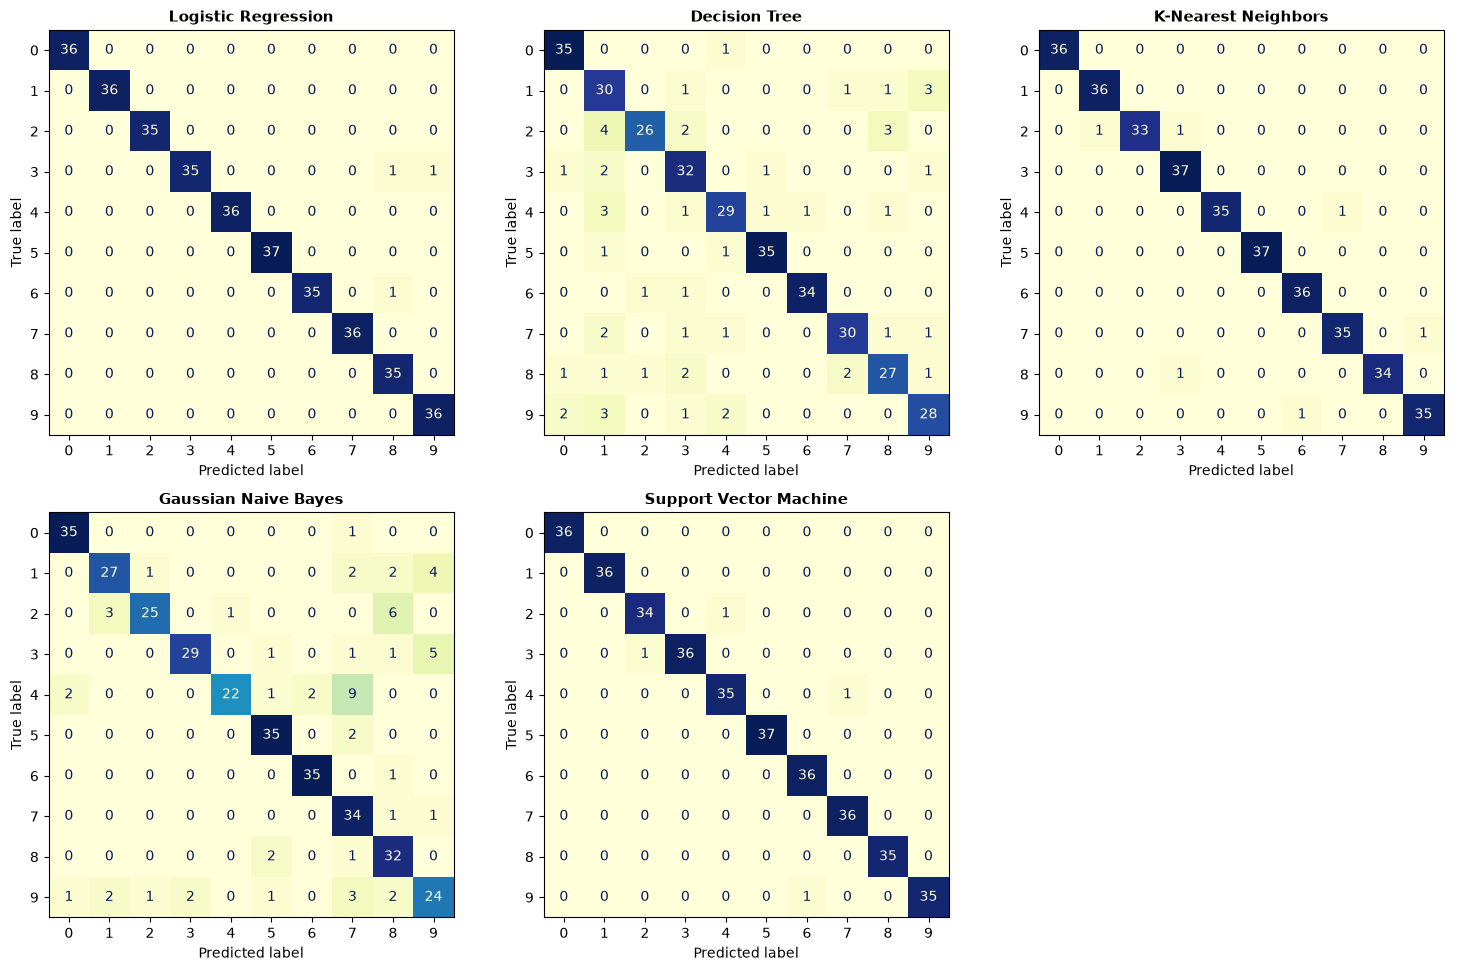

Logistic Regression    :  3 errors / 360 test rows
Decision Tree          : 54 errors / 360 test rows
K-Nearest Neighbors    :  6 errors / 360 test rows
Gaussian Naive Bayes   : 62 errors / 360 test rows
Support Vector Machine :  4 errors / 360 test rows


In [8]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9.8))
for ax, (name, cm) in zip(axs.flat, matrices.items()):
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
        ax=ax, cmap='YlGnBu', colorbar=False, values_format='d',
    )
    ax.set_title(name, fontsize=11, fontweight='bold')
axs.flat[-1].axis('off')
plt.tight_layout();plt.show()
for name, matrix in matrices.items():
    errors = int(matrix.sum() - np.trace(matrix))
    print(f'{name:23}: {errors:2} errors / {len(X_test)} test rows')

## 9 — Inspect classification errors

When reviewing the winning classifier, we display genuine misclassified digits. These are difficult cases to consider in the written observations; they must **not** be deleted from evaluation.

Winner: Logistic Regression | number of misclassifications: 3


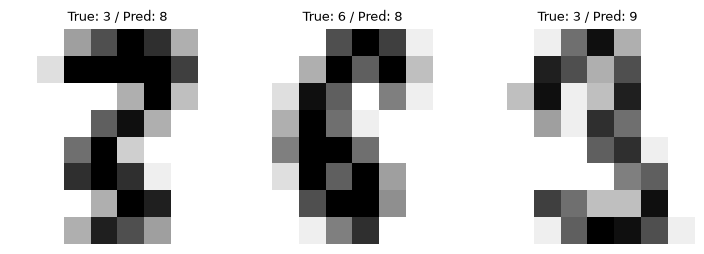

In [9]:
winner = winner_by_mcc(comparison)
win_scores, win_cm, win_pred, win_prob = evaluate(trained_models[winner], X_test, y_test)
incorrect_positions = np.flatnonzero(win_pred != y_test.to_numpy())
print('Winner:', winner, '| number of misclassifications:', len(incorrect_positions))
if len(incorrect_positions):
    subset = incorrect_positions[:min(8,len(incorrect_positions))]
    fig, axs = plt.subplots(1, len(subset), figsize=(2.4*len(subset), 2.5), squeeze=False)
    for index, ax in zip(subset, axs[0]):
        ax.imshow(X_test.iloc[index].to_numpy().reshape(8,8), cmap='binary', vmin=0, vmax=16)
        ax.set_title(f'True: {y_test.iloc[index]} / Pred: {win_pred[index]}', fontsize=9)
        ax.axis('off')
    plt.tight_layout();plt.show()

## 10 — Export complete fitted pipelines and labelled held-out CSV

The application only needs **saved pipelines**, `results/experiment.json`, and `test_data.csv`; it never needs training data. Export all five entire pipelines so the scaler is not lost. The metadata captures versions and the dataset fingerprint for reproducibility.

In [10]:
(ROOT / 'model').mkdir(exist_ok=True)
(ROOT / 'results').mkdir(exist_ok=True)
for name, filename in MODEL_FILES.items():
    joblib.dump(trained_models[name], ROOT / 'model' / filename, compress=3)
    print('Saved:', 'model/' + filename)
test_export = X_test.copy()
test_export[TARGET] = y_test.to_numpy()
test_export.to_csv(ROOT / 'test_data.csv', index=False)
comparison.to_csv(ROOT / 'results' / 'model_metrics.csv', index=False)
metadata = {
    'dataset': 'Optical Recognition of Handwritten Digits - UCI copy via scikit-learn',
    'rows_full': len(raw), 'n_features': len(PIXELS),
    'train_rows': len(X_train), 'test_rows': len(X_test),
    'split_seed': SEED, 'test_fraction': TEST_FRACTION,
    'target': TARGET, 'features': PIXELS, 'labels': CLASSES, 'models': MODEL_FILES,
    'metric_definitions': 'Macro precision/recall/F1 over ten classes; OvR macro multiclass AUC; multiclass MCC',
    'positive_class': None,
    'winner_rule': 'MCC first, F1 as a tie-breaker',
    'winner': winner,
    'versions': {'python': sys.version.split()[0], 'sklearn': sklearn.__version__,
                 'numpy': np.__version__, 'pandas': pd.__version__, 'joblib': joblib.__version__},
    'dataset_sha256': hashlib.sha256((ROOT/'data'/'digits_uci_subset.csv').read_bytes()).hexdigest(),
    'confusion_matrices': {name: cm.tolist() for name,cm in matrices.items()},
}
(ROOT / 'results' / 'experiment.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('Saved test_data.csv:', test_export.shape, '| all five model files and results/experiment.json')

Saved: model/logistic_regression.joblib
Saved: model/decision_tree.joblib
Saved: model/knn.joblib
Saved: model/naive_bayes.joblib
Saved: model/svm.joblib
Saved test_data.csv: (360, 65) | all five model files and results/experiment.json


## 11 — Reload every saved pipeline and independently verify metrics

The following check is important for deployment: `joblib.load()` must reproduce all six original numbers on the **exported CSV** without any model retraining.

In [11]:
independent_csv = pd.read_csv(ROOT / 'test_data.csv')
X_reloaded, y_reloaded = validate_labeled_csv(independent_csv)
for name, filename in MODEL_FILES.items():
    restored = joblib.load(ROOT / 'model' / filename)
    fresh_scores, cm, predictions, probs = evaluate(restored, X_reloaded, y_reloaded)
    original = comparison.set_index('ML Model Name').loc[name]
    for metric in METRICS:
        assert np.isclose(original[metric], fresh_scores[metric], atol=1e-12), (name,metric)
    assert np.allclose(probs.sum(axis=1), 1, atol=1e-8)
    print(f'PASS {name}: all six metrics reproduced')
print('No fitting performed during verification.')

PASS Logistic Regression: all six metrics reproduced
PASS Decision Tree: all six metrics reproduced
PASS K-Nearest Neighbors: all six metrics reproduced
PASS Gaussian Naive Bayes: all six metrics reproduced
PASS Support Vector Machine: all six metrics reproduced
No fitting performed during verification.


## 12 — Evidence-based observations and conclusion

| Model | Measured observation on the 360-image holdout |
|---|---|
| **Logistic Regression** | Accuracy **0.9917**, MCC **0.9908**, macro F1 **0.9917**; only **3 mistakes**. Its globally linear separation works exceptionally well on this standardized image representation. |
| **Decision Tree** | Accuracy **0.8500** and MCC **0.8340** with **54 mistakes**. A bounded-depth single tree uses hard splits, losing information about nuanced shared pixel patterns. |
| **KNN** | Accuracy **0.9833**, macro F1 **0.9833**, with **6 mistakes**; distance-based classification is highly effective after standardization, but inference retains stored training examples. |
| **Gaussian Naive Bayes** | Accuracy **0.8278**, MCC **0.8111**, **62 mistakes**; nearby pixels are related, which conflicts with its conditional independence assumption. |
| **Support Vector Machine** | Accuracy **0.9889**, MCC **0.9877**, **4 mistakes**, and the highest AUC **0.9999**. Nonlinear RBF scores rank digits particularly well; on this split it still trails Logistic Regression slightly on MCC/F1. |

**Overall winner for this dataset and held-out partition: Logistic Regression.** MCC is the selection metric, with macro F1 as a tie-breaker; **SVM is the AUC leader**. No model was tuned after looking at the test labels. Scores reflect a single partition of the curated UCI subset, not guaranteed performance on new writers.

**Limitations:** The source represents a subset of one classical dataset; random splits within that subset are not writer-independent evaluation. This is an educational comparison, not a production handwriting-recognition claim. Future work can explore repeated stratified cross-validation on training data or external author-separated test sets without changing the current holdout results.

## 13 — Streamlit demo and submission requirements

1. In the repository root, run `python verify_project.py` and `streamlit run app.py`.
2. Upload `test_data.csv` through the sidebar or select the bundled example; all **five** saved models can be compared. The app displays six metric cards, count/percentage confusion matrices, ten-class reports, an interactive pixel grid, comparison plots and downloadable predictions. **No training is performed in the app.**
3. Push the files to GitHub with genuine commits, deploy the **main / app.py** entry point to Community Cloud using **Python 3.13** and the pinned `requirements.txt`.
4. Run/verify this notebook or `train.py` in your own **BITS Virtual Lab** and capture **one genuine proof screenshot**. Do not reuse the example student's evidence.
5. Fill in the **real** GitHub link, live Streamlit link, screenshot and full README content using the provided report generator. Submit the **single final PDF** before the faculty's deadline.

Faculty instructions prohibit copy-paste AI submissions. Review, understand, adapt and independently validate the code and write-up before submitting.